In [ ]:
!pip install ---upgrade pip setuptools wheel


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: ---upgrade


In [ ]:
!pip install numpy>=1.22.0

In [ ]:
!pip install casualml lightgbm  matplotlib pandas

ERROR: Could not find a version that satisfies the requirement casualml (from versions: none)
ERROR: No matching distribution found for casualml


In [ ]:
!pip install econml lightgbm pandas matplotlib

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(1)
n_samples=10000
n_features=10
X=np.random.randn(n_samples,n_features)

treatment=np.random.binomial(1,0.5,size=n_samples)#50% get the ad and 50% dont get it

#Simulating customer purchases based on features and treatment
true_effect=0.3*X[:,0]+0.2*X[:,1]
baseline=0.2*X[:,2]
conversion_prob=1/(1+np.exp(-(baseline+treatment*true_effect)))
conversion=np.random.binomial(1,conversion_prob)

#putting it into a clean table(Dataframe)
feature_names=[f"feature_{i}" for i in range(n_features)]
df=pd.DataFrame(X,columns=feature_names)
df['treatment']=treatment
df['conversion']=conversion

x_names=feature_names
print(df)
print("Data generated successfully!")



      feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
0      1.624345  -0.611756  -0.528172  -1.072969   0.865408  -2.301539   
1      1.462108  -2.060141  -0.322417  -0.384054   1.133769  -1.099891   
2     -1.100619   1.144724   0.901591   0.502494   0.900856  -0.683728   
3     -0.691661  -0.396754  -0.687173  -0.845206  -0.671246  -0.012665   
4     -0.191836  -0.887629  -0.747158   1.692455   0.050808  -0.636996   
...         ...        ...        ...        ...        ...        ...   
9995  -0.037656   0.287027   0.029254   0.457600   0.374025  -0.745675   
9996   1.004368  -0.983595   1.241610   0.269255  -0.775113   1.353163   
9997   0.429098  -1.492802   0.853288  -0.063169  -0.313412   1.518369   
9998   3.286562  -0.639205   1.646028  -0.004282   0.329175   1.037583   
9999  -0.643374   0.991160  -2.437732   1.162871   1.256108   0.203396   

      feature_6  feature_7  feature_8  feature_9  treatment  conversion  
0      1.744812  -0.761207   0.319039

In [ ]:
from econml.metalearners import XLearner
from lightgbm import LGBMRegressor,LGBMClassifier
xl=XLearner(models=LGBMRegressor(random_state=42),
            propensity_model=LGBMClassifier(random_state=42)
            )
X_data=df[x_names].values
treatment_data=df['treatment'].values
y_data=df['conversion'].values

xl.fit(Y=y_data,T=treatment_data,X=X_data)
df['uplift_score']=xl.effect(X_data).flatten()
print(df[['uplift_score']])
print("X-Learner Trained successfully!")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


      uplift_score
0         0.344588
1        -0.171212
2        -0.208113
3        -0.148781
4        -0.214365
...            ...
9995     -0.007762
9996      0.022167
9997     -0.185070
9998      0.284448
9999      0.188463

[10000 rows x 1 columns]
X-Learner Trained successfully!


In [ ]:
budget_fraction=0.20
threshold=df['uplift_score'].quantile(1-budget_fraction)
targeted_customers=df['uplift_score']>=threshold

incremental_conversions=df[targeted_customers&(df['treatment']==1)]['conversion'].sum()
print(f"Incremental conversions captured within top 20% budget:{incremental_conversions}")
print("Budget simulation finished")

Incremental conversions captured within top 20% budget:879
Budget simulation finished


In [ ]:
import matplotlib.pyplot as plt
eval_df=pd.DataFrame({
    'conversion':y_data,
    'treatment':treatment_data,
    'uplift_score':df['uplift_score'].values

})
eval_df=eval_df.sort_values(by='uplift_score',ascending=False).reset_index(drop=True)
eval_df['t_count']=eval_df['treatment'].cumsum()
eval_df['c_count']=(1-eval_df['treatment']).cumsum()

total_t=eval_df['treatment'].sum()
total_c=(1-eval_df['treatment']).sum()

eval_df['t_gain']=(eval_df['conversion']*eval_df['treatment']).cumsum()
eval_df['c_gain']=(eval_df['conversion']*(1-eval_df['treatment'])).cumsum()

eval_df['cumulative_uplift']=eval_df['t_gain']-(eval_df['t_count']/total_c)*eval_df['c_gain']


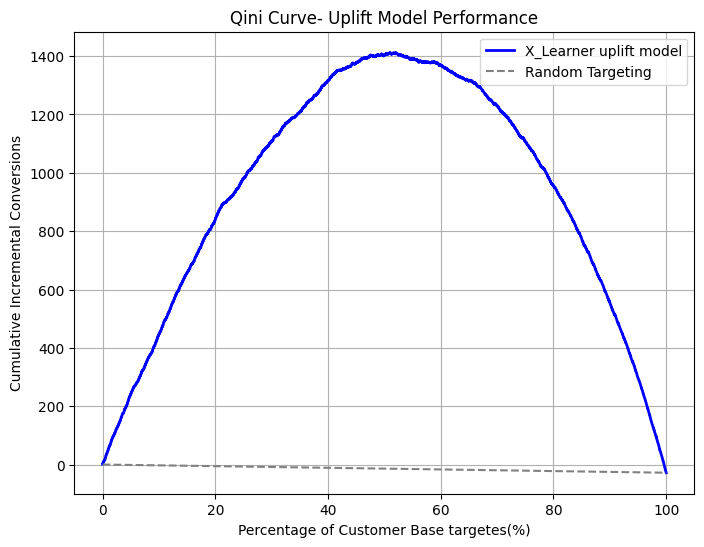

In [ ]:
plt.figure(figsize=(8,6))
plt.plot(np.linspace(0,100,len(eval_df)),eval_df['cumulative_uplift'],label='X_Learner uplift model',color='blue',lw=2)
plt.plot([0,100],[0,eval_df['cumulative_uplift'].iloc[-1]],label='Random Targeting',linestyle='--',color='gray')
plt.xlabel('Percentage of Customer Base targetes(%)')
plt.ylabel('Cumulative Incremental Conversions')
plt.title('Qini Curve- Uplift Model Performance')
plt.legend()
plt.grid(True)
plt.show()